# Week 2: Data Preprocessing and Feature Engineering

## Project Title
AI-Based Bike Rental Demand Prediction Using Machine Learning

## Objective
The objective of this week is to preprocess the Capital Bikeshare trip-history dataset and prepare it for machine learning-based bike rental demand prediction.

The October 2025 dataset contains individual bike rental records. These records will be cleaned, analyzed, and aggregated into hourly rental demand.

## Dataset
- Source: Capital Bikeshare System Data
- Dataset: October 2025 trip-history data
- File: `202510-capitalbikeshare-tripdata.csv`
- Original records: 624,869
- Original features: 13

## Tools and Libraries
- Python
- Google Colab
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

## Main Activities
1. Dataset loading and inspection
2. Data cleaning and missing-value handling
3. Outlier detection
4. Exploratory data analysis
5. Hourly demand aggregation
6. Feature extraction and engineering
7. Categorical encoding and numerical scaling
8. Exporting the processed dataset

In [35]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Dataset Loading

The Capital Bikeshare October 2025 dataset is loaded into a Pandas DataFrame. The dataset contains individual bike rental records, including ride timestamps, bike types, station details, geographical coordinates, and customer categories.

In [2]:
from google.colab import files

uploaded = files.upload()

Saving 202510-capitalbikeshare-tripdata.csv to 202510-capitalbikeshare-tripdata.csv


In [3]:
# Load the uploaded dataset

file_name = "202510-capitalbikeshare-tripdata.csv"

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (624869, 13)


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,134E8A6335D83665,electric_bike,2025-10-24 12:32:24.291,2025-10-24 12:35:39.839,20th & Q St NW,31982.0,20th St & Columbia Rd NW,31133.0,38.911086,-77.045061,38.918103,-77.045469,member
1,85E9CB578BFB231F,classic_bike,2025-10-03 17:53:59.401,2025-10-03 18:05:13.643,2nd St & Massachusetts Ave NE,31641.0,7th & F St NW / National Portrait Gallery,31232.0,38.894972,-77.003135,38.897324,-77.022216,member
2,2F3D12B56D075EE7,electric_bike,2025-10-07 13:26:46.128,2025-10-07 13:40:50.716,4th & C St SW,31243.0,10th St & Constitution Ave NW,31219.0,38.886372,-77.017701,38.893028,-77.026013,casual
3,2D1AB91A0B8C5491,electric_bike,2025-10-06 18:12:17.271,2025-10-06 18:17:08.397,15th St & Constitution Ave NW,31321.0,14th & L St NW,31283.0,38.892244,-77.033234,38.903658,-77.031737,member
4,3C2128E4A371A46A,electric_bike,2025-10-27 13:25:26.473,2025-10-27 13:30:57.999,Virginia Ave & C St NW,31261.0,18th & L St NW,31224.0,38.894112,-77.044334,38.903741,-77.042452,member


## 2. Dataset Understanding

The dataset is examined to understand its structure, column names, data types, and statistical information. This helps identify the data that requires cleaning and transformation.


In [4]:
df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,134E8A6335D83665,electric_bike,2025-10-24 12:32:24.291,2025-10-24 12:35:39.839,20th & Q St NW,31982.0,20th St & Columbia Rd NW,31133.0,38.911086,-77.045061,38.918103,-77.045469,member
1,85E9CB578BFB231F,classic_bike,2025-10-03 17:53:59.401,2025-10-03 18:05:13.643,2nd St & Massachusetts Ave NE,31641.0,7th & F St NW / National Portrait Gallery,31232.0,38.894972,-77.003135,38.897324,-77.022216,member
2,2F3D12B56D075EE7,electric_bike,2025-10-07 13:26:46.128,2025-10-07 13:40:50.716,4th & C St SW,31243.0,10th St & Constitution Ave NW,31219.0,38.886372,-77.017701,38.893028,-77.026013,casual
3,2D1AB91A0B8C5491,electric_bike,2025-10-06 18:12:17.271,2025-10-06 18:17:08.397,15th St & Constitution Ave NW,31321.0,14th & L St NW,31283.0,38.892244,-77.033234,38.903658,-77.031737,member
4,3C2128E4A371A46A,electric_bike,2025-10-27 13:25:26.473,2025-10-27 13:30:57.999,Virginia Ave & C St NW,31261.0,18th & L St NW,31224.0,38.894112,-77.044334,38.903741,-77.042452,member


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 624869
Columns: 13


In [6]:
print(df.columns.tolist())

['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 624869 entries, 0 to 624868
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   ride_id             624869 non-null  object 
 1   rideable_type       624869 non-null  object 
 2   started_at          624869 non-null  object 
 3   ended_at            624869 non-null  object 
 4   start_station_name  543240 non-null  object 
 5   start_station_id    543240 non-null  float64
 6   end_station_name    538918 non-null  object 
 7   end_station_id      538711 non-null  float64
 8   start_lat           624869 non-null  float64
 9   start_lng           624869 non-null  float64
 10  end_lat             624527 non-null  float64
 11  end_lng             624527 non-null  float64
 12  member_casual       624869 non-null  object 
dtypes: float64(6), object(7)
memory usage: 62.0+ MB


In [8]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ride_id,624869,624869,134E8A6335D83665,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rideable_type,624869,2,electric_bike,410268,NaN,NaN,NaN,NaN,NaN,NaN,NaN
started_at,624869,624727,2025-10-24 18:44:47.942,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ended_at,624869,624558,2025-10-28 10:32:24.748,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
start_station_name,543240,820,Columbus Circle / Union Station,5820,NaN,NaN,NaN,NaN,NaN,NaN,NaN
start_station_id,543240.0,NaN,NaN,NaN,31407.16385,334.726827,30200.0,31210.0,31297.0,31615.0,33200.0
end_station_name,538918,819,Columbus Circle / Union Station,5862,NaN,NaN,NaN,NaN,NaN,NaN,NaN
end_station_id,538711.0,NaN,NaN,NaN,31408.513496,336.933423,30200.0,31212.0,31296.0,31616.0,33200.0
start_lat,624869.0,NaN,NaN,NaN,38.90664,0.027511,38.766844,38.894851,38.905697,38.92,39.13
start_lng,624869.0,NaN,NaN,NaN,-77.033362,0.036127,-77.42,-77.04564,-77.031737,-77.012289,-76.81


In [9]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
ride_id                   0
rideable_type             0
started_at                0
ended_at                  0
start_station_name    81629
start_station_id      81629
end_station_name      85951
end_station_id        86158
start_lat                 0
start_lng                 0
end_lat                 342
end_lng                 342
member_casual             0
dtype: int64


## 3. Data Cleaning

Data cleaning is performed to improve the quality and consistency of the dataset.

The following operations are carried out:

- Remove duplicate ride records.
- Convert timestamp columns into datetime format.
- Check for invalid timestamps.
- Calculate ride duration.
- Identify missing values.
- Investigate unusually long rides.

Rows with missing station details are retained because their ride timestamps are still useful for hourly demand prediction.


In [10]:
# Keep the original DataFrame unchanged

cleaned_df = df.copy()

print("Working copy created.")

Working copy created.


In [11]:
print("Duplicate ride IDs before cleaning:",
      cleaned_df['ride_id'].duplicated().sum())

cleaned_df = cleaned_df.drop_duplicates(
    subset='ride_id'
).copy()

print("Shape after duplicate removal:", cleaned_df.shape)

Duplicate ride IDs before cleaning: 0
Shape after duplicate removal: (624869, 13)


In [12]:
cleaned_df['started_at'] = pd.to_datetime(
    cleaned_df['started_at'],
    errors='coerce'
)

cleaned_df['ended_at'] = pd.to_datetime(
    cleaned_df['ended_at'],
    errors='coerce'
)

print(cleaned_df[['started_at', 'ended_at']].dtypes)

started_at    datetime64[ns]
ended_at      datetime64[ns]
dtype: object


In [13]:
before = len(cleaned_df)

cleaned_df = cleaned_df.dropna(
    subset=['started_at', 'ended_at']
).copy()

print("Invalid timestamp records removed:",
      before - len(cleaned_df))

Invalid timestamp records removed: 0


In [14]:
cleaned_df['ride_duration_minutes'] = (
    cleaned_df['ended_at'] - cleaned_df['started_at']
).dt.total_seconds() / 60

cleaned_df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,ride_duration_minutes
0,134E8A6335D83665,electric_bike,2025-10-24 12:32:24.291,2025-10-24 12:35:39.839,20th & Q St NW,31982.0,20th St & Columbia Rd NW,31133.0,38.911086,-77.045061,38.918103,-77.045469,member,3.259133
1,85E9CB578BFB231F,classic_bike,2025-10-03 17:53:59.401,2025-10-03 18:05:13.643,2nd St & Massachusetts Ave NE,31641.0,7th & F St NW / National Portrait Gallery,31232.0,38.894972,-77.003135,38.897324,-77.022216,member,11.237367
2,2F3D12B56D075EE7,electric_bike,2025-10-07 13:26:46.128,2025-10-07 13:40:50.716,4th & C St SW,31243.0,10th St & Constitution Ave NW,31219.0,38.886372,-77.017701,38.893028,-77.026013,casual,14.076467
3,2D1AB91A0B8C5491,electric_bike,2025-10-06 18:12:17.271,2025-10-06 18:17:08.397,15th St & Constitution Ave NW,31321.0,14th & L St NW,31283.0,38.892244,-77.033234,38.903658,-77.031737,member,4.852100
4,3C2128E4A371A46A,electric_bike,2025-10-27 13:25:26.473,2025-10-27 13:30:57.999,Virginia Ave & C St NW,31261.0,18th & L St NW,31224.0,38.894112,-77.044334,38.903741,-77.042452,member,5.525433


In [15]:
before = len(cleaned_df)

cleaned_df = cleaned_df[
    cleaned_df['ride_duration_minutes'] >= 0
].copy()

print("Invalid negative-duration records removed:",
      before - len(cleaned_df))

Invalid negative-duration records removed: 0


In [16]:
station_columns = [
    'start_station_name',
    'end_station_name'
]

for column in station_columns:
    cleaned_df[column] = cleaned_df[column].fillna('Unknown')

print("Missing station names after handling:")
print(cleaned_df[station_columns].isnull().sum())

Missing station names after handling:
start_station_name    0
end_station_name      0
dtype: int64


## 4. Outlier Detection

Outliers are unusual values that differ significantly from the general distribution of the data.

The Interquartile Range (IQR) method is used to identify unusually long ride durations.

Outliers are investigated rather than automatically removed because some long rides may represent genuine customer behavior.


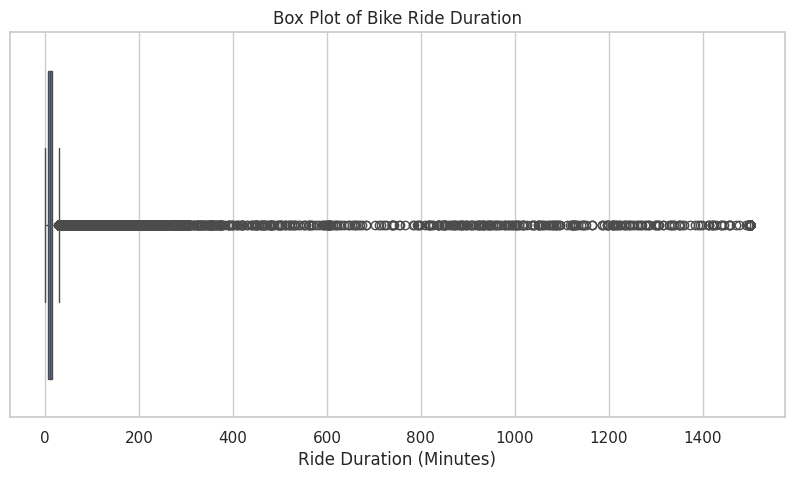

In [17]:
# Visualize ride duration

plt.figure(figsize=(10, 5))
sns.boxplot(x=cleaned_df['ride_duration_minutes'])

plt.title("Box Plot of Bike Ride Duration")
plt.xlabel("Ride Duration (Minutes)")
plt.show()

In [18]:
Q1 = cleaned_df['ride_duration_minutes'].quantile(0.25)
Q3 = cleaned_df['ride_duration_minutes'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = cleaned_df[
    (cleaned_df['ride_duration_minutes'] < lower_limit) |
    (cleaned_df['ride_duration_minutes'] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of outliers:", len(outliers))

Lower limit: -9.068100000000001
Upper limit: 29.617766666666668
Number of outliers: 44719


## 5. Date Filtering

The dataset is filtered to include rides starting between October 1 and October 31, 2025. This ensures that the demand analysis is based on the selected monthly dataset.

In [19]:
october_df = cleaned_df[
    (cleaned_df['started_at'] >= '2025-10-01') &
    (cleaned_df['started_at'] < '2025-11-01')
].copy()

print("October dataset shape:", october_df.shape)
print("First ride:", october_df['started_at'].min())
print("Last ride:", october_df['started_at'].max())

October dataset shape: (624816, 14)
First ride: 2025-10-01 00:00:10.538000
Last ride: 2025-10-31 23:58:10.050000


## 6. Exploratory Data Analysis

Exploratory Data Analysis is performed using statistical summaries and visualizations.

The analysis includes:

- Distribution of bike types.
- Comparison of member and casual riders.
- Ride duration distribution.
- Rental activity over time.

These visualizations help identify customer behavior and patterns in bike usage.

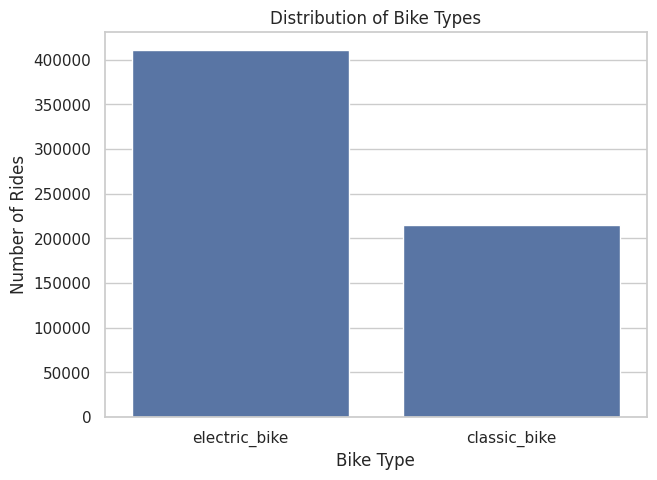

In [20]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=october_df,
    x='rideable_type'
)

plt.title("Distribution of Bike Types")
plt.xlabel("Bike Type")
plt.ylabel("Number of Rides")
plt.show()

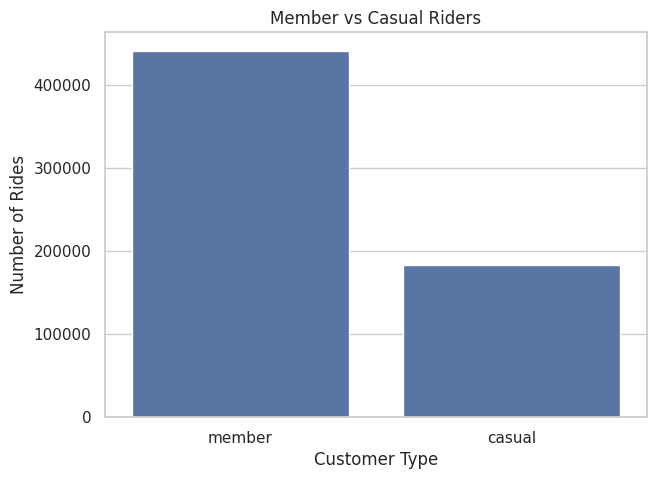

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=october_df,
    x='member_casual'
)

plt.title("Member vs Casual Riders")
plt.xlabel("Customer Type")
plt.ylabel("Number of Rides")
plt.show()

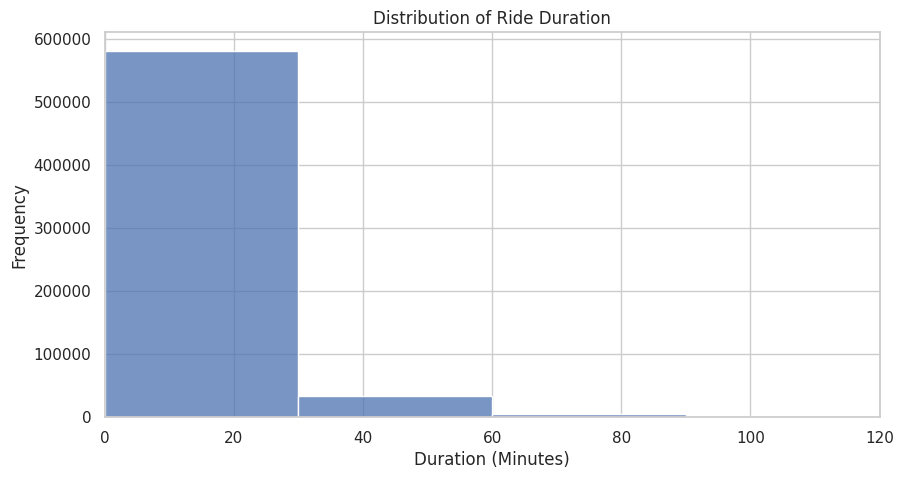

In [22]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=october_df,
    x='ride_duration_minutes',
    bins=50
)

plt.xlim(0, 120)
plt.title("Distribution of Ride Duration")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Frequency")
plt.show()

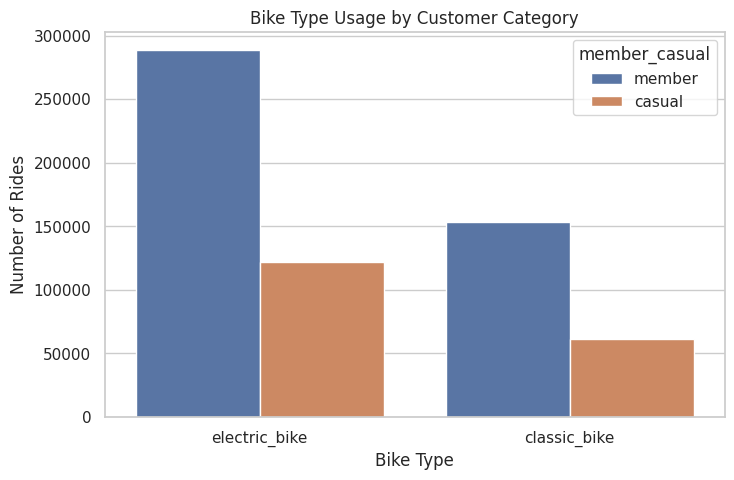

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=october_df,
    x='rideable_type',
    hue='member_casual'
)

plt.title("Bike Type Usage by Customer Category")
plt.xlabel("Bike Type")
plt.ylabel("Number of Rides")
plt.show()

## 7. Hourly Rental Demand Aggregation

The original trip-level dataset is converted into an hourly demand dataset.

Each ride is grouped according to its starting hour. The number of rides in each hour is calculated as the rental demand.

The resulting target variable is `rental_count`, which represents the number of bike rentals during a particular hour.


In [24]:
# Group rides by their starting hour

hourly_demand = (
    october_df
    .set_index('started_at')
    .resample('h')
    .size()
    .rename('rental_count')
    .reset_index()
)

hourly_demand.rename(
    columns={'started_at': 'hour_timestamp'},
    inplace=True
)

print("Hourly dataset shape:", hourly_demand.shape)

hourly_demand.head(10)

Hourly dataset shape: (744, 2)


,hour_timestamp,rental_count
0,2025-10-01 00:00:00,147
1,2025-10-01 01:00:00,63
2,2025-10-01 02:00:00,21
3,2025-10-01 03:00:00,15
4,2025-10-01 04:00:00,50
5,2025-10-01 05:00:00,153
6,2025-10-01 06:00:00,466
7,2025-10-01 07:00:00,1148
8,2025-10-01 08:00:00,2097
9,2025-10-01 09:00:00,1200


In [25]:
# Create a complete hourly timeline for October

full_hours = pd.date_range(
    start='2025-10-01 00:00:00',
    end='2025-10-31 23:00:00',
    freq='h'
)

hourly_demand = (
    hourly_demand
    .set_index('hour_timestamp')
    .reindex(full_hours, fill_value=0)
    .rename_axis('hour_timestamp')
    .reset_index()
)

print("Total hourly records:", len(hourly_demand))
print(hourly_demand.head())

Total hourly records: 744
       hour_timestamp  rental_count
0 2025-10-01 00:00:00           147
1 2025-10-01 01:00:00            63
2 2025-10-01 02:00:00            21
3 2025-10-01 03:00:00            15
4 2025-10-01 04:00:00            50


## 8. Hourly Demand Visualization

The hourly rental demand is visualized using a line chart to understand changes in bike rental activity throughout October 2025.

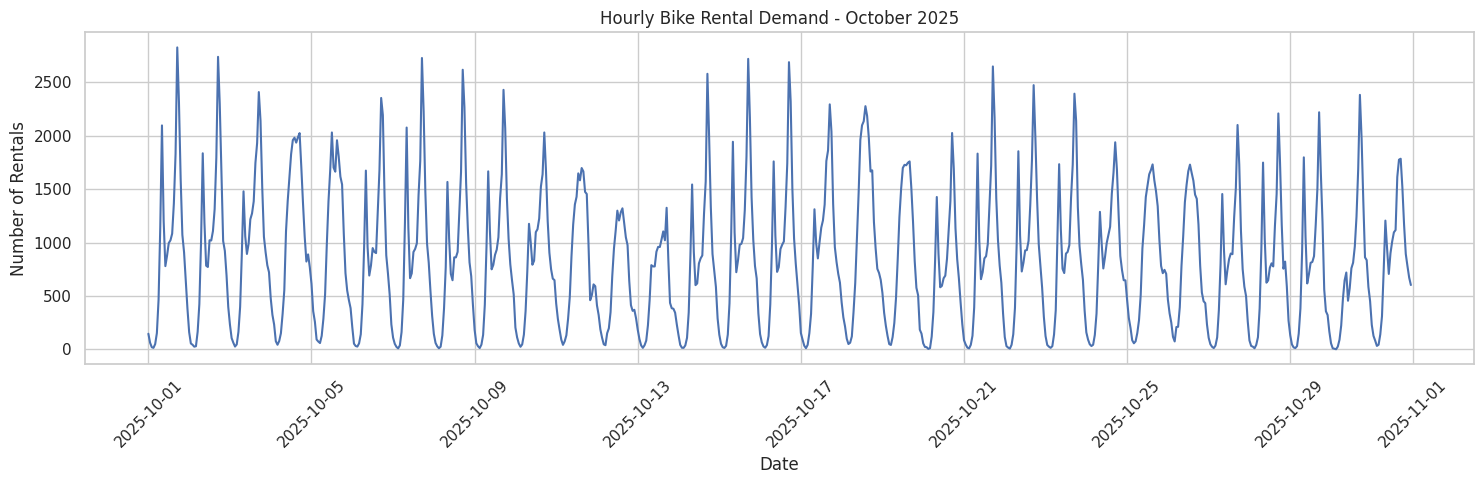

In [26]:
plt.figure(figsize=(15, 5))

plt.plot(
    hourly_demand['hour_timestamp'],
    hourly_demand['rental_count']
)

plt.title("Hourly Bike Rental Demand - October 2025")
plt.xlabel("Date")
plt.ylabel("Number of Rentals")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Feature Engineering

Feature engineering is used to extract useful information from the timestamp column.

The following features are created:

| Feature | Description | Expected benefit |
|---|---|---|
| hour | Hour of the day | Captures daily demand patterns |
| day_of_week | Day number | Captures weekday and weekend patterns |
| month | Month of the year | Captures seasonal variation |
| is_weekend | Weekend indicator | Identifies weekend behavior |
| is_rush_hour | Rush-hour indicator | Captures commuting demand |
| hour_sin and hour_cos | Cyclic hour features | Represents the repeating nature of time |

These features help machine learning models understand temporal patterns in bike rental demand.

In [27]:
# Extract date and time features

hourly_demand['hour'] = (
    hourly_demand['hour_timestamp'].dt.hour
)

hourly_demand['day_of_week'] = (
    hourly_demand['hour_timestamp'].dt.dayofweek
)

hourly_demand['month'] = (
    hourly_demand['hour_timestamp'].dt.month
)

hourly_demand['day'] = (
    hourly_demand['hour_timestamp'].dt.day
)

# Weekend: Saturday = 5, Sunday = 6

hourly_demand['is_weekend'] = (
    hourly_demand['day_of_week'] >= 5
).astype(int)

# Rush hour: morning 7-9 and evening 16-19

hourly_demand['is_rush_hour'] = (
    hourly_demand['hour'].isin([7, 8, 9, 16, 17, 18, 19])
).astype(int)

# Cyclic encoding for hour

hourly_demand['hour_sin'] = np.sin(
    2 * np.pi * hourly_demand['hour'] / 24
)

hourly_demand['hour_cos'] = np.cos(
    2 * np.pi * hourly_demand['hour'] / 24
)

hourly_demand.head()

,hour_timestamp,rental_count,hour,day_of_week,month,day,is_weekend,is_rush_hour,hour_sin,hour_cos
0,2025-10-01 00:00:00,147,0,2,10,1,0,0,0.000000,1.000000
1,2025-10-01 01:00:00,63,1,2,10,1,0,0,0.258819,0.965926
2,2025-10-01 02:00:00,21,2,2,10,1,0,0,0.500000,0.866025
3,2025-10-01 03:00:00,15,3,2,10,1,0,0,0.707107,0.707107
4,2025-10-01 04:00:00,50,4,2,10,1,0,0,0.866025,0.500000


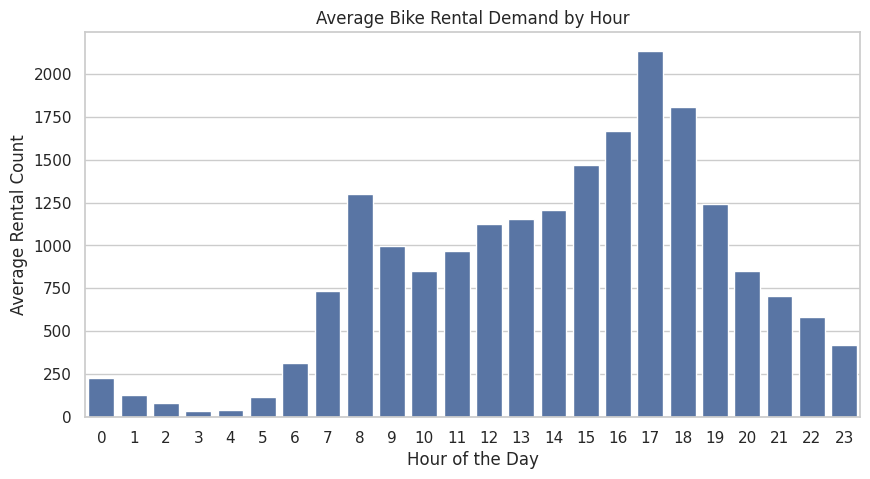

In [28]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=hourly_demand,
    x='hour',
    y='rental_count',
    errorbar=None
)

plt.title("Average Bike Rental Demand by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rental Count")
plt.show()

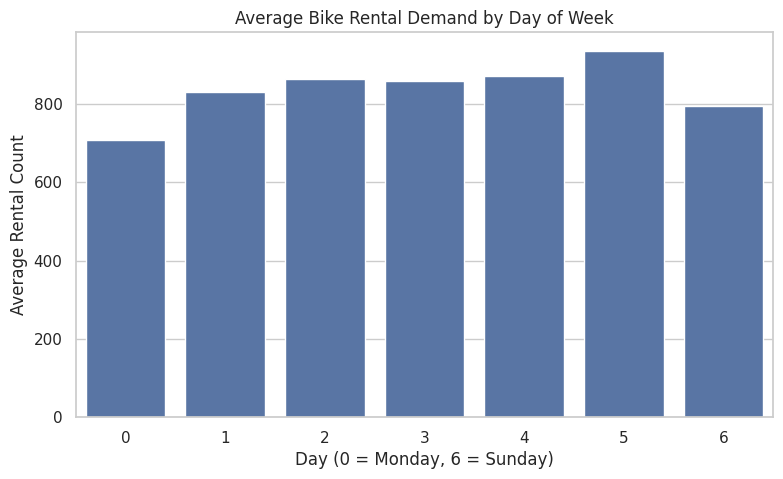

In [29]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=hourly_demand,
    x='day_of_week',
    y='rental_count',
    errorbar=None
)

plt.title("Average Bike Rental Demand by Day of Week")
plt.xlabel("Day (0 = Monday, 6 = Sunday)")
plt.ylabel("Average Rental Count")
plt.show()

## 10. Categorical Encoding

Categorical variables are converted into numerical representations using One-Hot Encoding.

The `rideable_type` and `member_casual` columns are selected as examples.

One-Hot Encoding creates separate binary columns for each category, allowing machine learning algorithms to process categorical information without assuming an artificial numerical order.

In [30]:
# Select categorical columns

categorical_data = october_df[
    ['rideable_type', 'member_casual']
].head(10)

# Apply One-Hot Encoding

encoded_data = pd.get_dummies(
    categorical_data,
    columns=['rideable_type', 'member_casual'],
    dtype=int
)

print("Original categorical data:")
display(categorical_data)

print("Encoded data:")
display(encoded_data)

Original categorical data:


,rideable_type,member_casual
0,electric_bike,member
1,classic_bike,member
2,electric_bike,casual
3,electric_bike,member
4,electric_bike,member
5,electric_bike,member
6,classic_bike,member
7,electric_bike,member
8,electric_bike,member
9,electric_bike,member


Encoded data:


,rideable_type_classic_bike,rideable_type_electric_bike,member_casual_casual,member_casual_member
0,0,1,0,1
1,1,0,0,1
2,0,1,1,0
3,0,1,0,1
4,0,1,0,1
5,0,1,0,1
6,1,0,0,1
7,0,1,0,1
8,0,1,0,1
9,0,1,0,1


## 11. Numerical Feature Scaling

StandardScaler is used to standardize numerical features.

It transforms the features using their mean and standard deviation.

The dataset is divided chronologically into training and testing portions. The scaler is fitted only on training data to prevent information from the test set leaking into the training process.

The target variable `rental_count` is not scaled in this preprocessing demonstration.

In [31]:
# Select features for the demonstration

feature_columns = [
    'hour',
    'day_of_week',
    'month',
    'day',
    'is_weekend',
    'is_rush_hour',
    'hour_sin',
    'hour_cos'
]

X = hourly_demand[feature_columns]
y = hourly_demand['rental_count']

# Chronological 80:20 split

split_index = int(len(hourly_demand) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

# Scale numerical features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)
print("Scaling completed successfully!")

Training data: (595, 8)
Testing data: (149, 8)
Scaling completed successfully!


## 12. Final Data Validation

The processed hourly dataset is checked to ensure that:

- No duplicate hourly timestamps exist.
- Rental counts are non-negative.
- Required engineered features are available.
- Missing values are handled.
- The dataset contains the expected number of hourly records.

In [32]:
print("Total hourly records:", len(hourly_demand))

print(
    "Duplicate timestamps:",
    hourly_demand['hour_timestamp'].duplicated().sum()
)

print(
    "Missing values:",
    hourly_demand.isnull().sum().sum()
)

print(
    "Negative rental counts:",
    (hourly_demand['rental_count'] < 0).sum()
)

print("\nFinal dataset columns:")
print(hourly_demand.columns.tolist())

print("\nFinal dataset preview:")
display(hourly_demand.head())

Total hourly records: 744
Duplicate timestamps: 0
Missing values: 0
Negative rental counts: 0

Final dataset columns:
['hour_timestamp', 'rental_count', 'hour', 'day_of_week', 'month', 'day', 'is_weekend', 'is_rush_hour', 'hour_sin', 'hour_cos']

Final dataset preview:


,hour_timestamp,rental_count,hour,day_of_week,month,day,is_weekend,is_rush_hour,hour_sin,hour_cos
0,2025-10-01 00:00:00,147,0,2,10,1,0,0,0.000000,1.000000
1,2025-10-01 01:00:00,63,1,2,10,1,0,0,0.258819,0.965926
2,2025-10-01 02:00:00,21,2,2,10,1,0,0,0.500000,0.866025
3,2025-10-01 03:00:00,15,3,2,10,1,0,0,0.707107,0.707107
4,2025-10-01 04:00:00,50,4,2,10,1,0,0,0.866025,0.500000


## 13. Saving the Processed Dataset

The final hourly dataset is exported as a CSV file. This file will be used in the upcoming machine learning model development phase.

The processed dataset contains the hourly rental demand target and engineered time-based features.

In [33]:
# Save processed hourly dataset

output_file = "processed_bike_rental_demand_october_2025.csv"

hourly_demand.to_csv(
    output_file,
    index=False
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [34]:
from google.colab import files

files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Conclusion

In Week 2, the Capital Bikeshare October 2025 trip-history dataset was successfully prepared for bike rental demand prediction.

The original trip-level data was inspected, cleaned, and analyzed. Missing station information was handled, duplicate records were checked, and unusually long ride durations were investigated using the IQR method.

The individual bike rental records were aggregated into hourly rental demand. New time-based features, including hour, day of the week, weekend indicator, rush-hour indicator, and cyclic time features, were created.

Exploratory visualizations were generated to understand bike usage patterns. Categorical encoding and numerical scaling were also demonstrated.

The final processed dataset was exported as a CSV file for use in the upcoming machine learning model development phase.

This completes the main data preprocessing and feature engineering activities for Week 2.